# Logística Baja California
## Fase 1: Exploración Inicial

In [1]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

df = pd.read_csv('logistica_baja_california.csv')

display(df.head(5))

display(df)

,Latitud,Longitud,Tipo_Solicitud
0,32.520796,-116.992084,Recoleccion
1,32.566198,-117.046102,Recoleccion
2,32.461507,-117.062417,Viaje_Pasajero
3,32.510667,-117.023516,Viaje_Pasajero
4,32.498468,-117.019210,Viaje_Pasajero


,Latitud,Longitud,Tipo_Solicitud
0,32.520796,-116.992084,Recoleccion
1,32.566198,-117.046102,Recoleccion
2,32.461507,-117.062417,Viaje_Pasajero
3,32.510667,-117.023516,Viaje_Pasajero
4,32.498468,-117.019210,Viaje_Pasajero
...,...,...,...
3095,30.614182,-115.940517,Recoleccion
3096,30.595910,-115.935556,Viaje_Pasajero
3097,30.567854,-115.915721,Viaje_Pasajero
3098,30.583558,-115.964736,Entrega_Paquete


In [2]:
X = df[['Latitud', 'Longitud']]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Matriz: ", X_scaled.shape)
print("Media: ", np.mean(X_scaled, axis=0))
print("Media antes de escalar: ", np.mean(X, axis=0))
print("Desviación estándar: ", np.std(X_scaled, axis=0))

Matriz:  (3100, 2)
Media:  [-9.31498606e-15 -1.84832794e-14]
Media antes de escalar:  Latitud      32.194303
Longitud   -116.803218
dtype: float64
Desviación estándar:  [1. 1.]


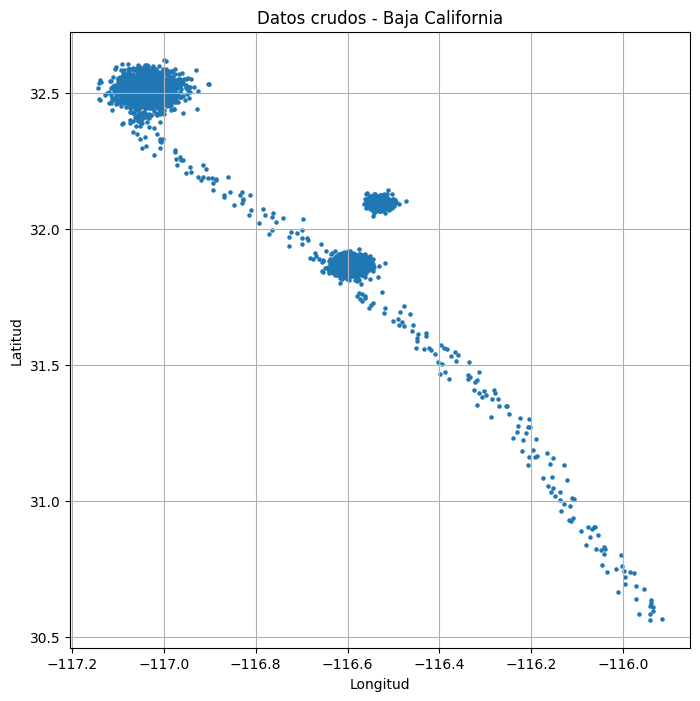

In [3]:
plt.figure(figsize=(8, 8))
plt.scatter(df['Longitud'], df['Latitud'], s=5)
plt.title('Datos crudos - Baja California')
plt.xlabel('Longitud')
plt.ylabel('Latitud')
plt.grid()
plt.show()

## Fase 2: Misión Estratégica 

**Algoritmo:** K-Means, porque necesitamos exactamente 3 centros que minimicen la distancia de todos los puntos a su centro.

In [4]:
kmeans = KMeans(n_clusters=3, n_init=10, random_state=42)

etiquetas_km = kmeans.fit_predict(X_scaled)

# Regresamos los centros a coordenadas reales (lat, lon)
centros = scaler.inverse_transform(kmeans.cluster_centers_)

print("Puntos por cluster: ", np.bincount(etiquetas_km))
print("Centros (Latitud, Longitud):")
print(centros)

Puntos por cluster:  [1611   95 1394]
Centros (Latitud, Longitud):
[[  32.50631573 -117.03496385]
 [  31.04053982 -116.13802721]
 [  31.91234754 -116.58072818]]


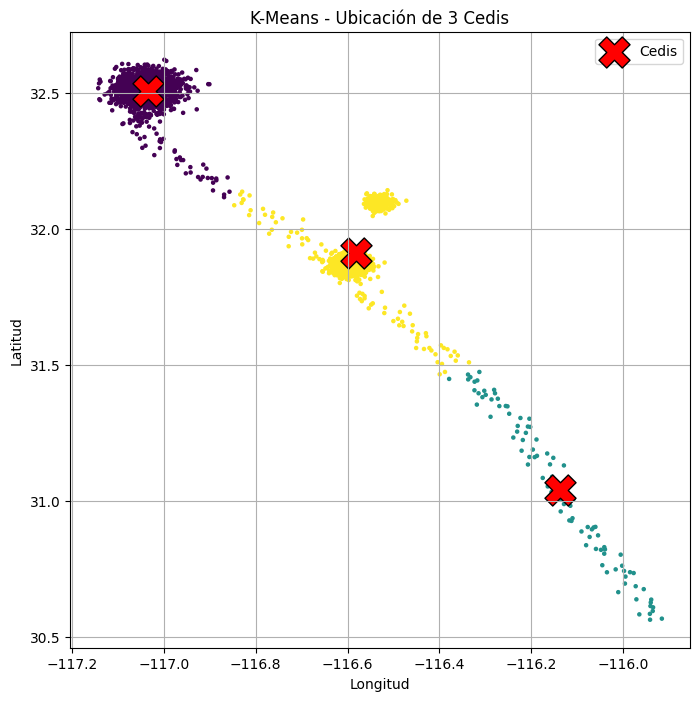

In [5]:
plt.figure(figsize=(8, 8))
plt.scatter(df['Longitud'], df['Latitud'], c=etiquetas_km, cmap='viridis', s=5)
plt.scatter(centros[:, 1], centros[:, 0], c='red', marker='X', s=500, edgecolors='black', label='Cedis')
plt.title('K-Means - Ubicación de 3 Cedis')
plt.xlabel('Longitud')
plt.ylabel('Latitud')
plt.legend()
plt.grid()
plt.show()

**¿Dónde colocó el algoritmo las Cedis? ¿Hacen sentido?**

Los coloco en donde se concentraban mas los puntos, en este caso quedaria en Tijuana y otro en Ensenada, pero el caso de San Quintin queda un poco al aire debido a que queda muy disperso a comparacion de los demas.

**¿Por qué la matemática provocó esto?**

K-Means minimiza la suma de distancias al cuadrado y obliga a todos los puntos a pertenecer a un cluster. Los puntos aislados del sur están muy lejos y, al elevar la distancia al cuadrado, pesan mucho, así que el algoritmo prefiere "gastar" un centro en ellos y jala ese centroide (que es un promedio) hacia la zona rural.

## Fase 3: Misión Operativa (Mapa de Tráfico y Zonas Calientes)

**Algoritmo:** DBSCAN, porque agrupa por densidad.

In [6]:
dbscan = DBSCAN(eps=0.1, min_samples=20)

etiquetas_db = dbscan.fit_predict(X_scaled)

df['Cluster'] = etiquetas_db

print("Clusters encontrados: ", len(set(etiquetas_db)) - (1 if -1 in etiquetas_db else 0))
print("Puntos de ruido: ", np.sum(etiquetas_db == -1))
display(df['Cluster'].value_counts())

Clusters encontrados:  3
Puntos de ruido:  212


Cluster
 0    1569
 1    1019
 2     300
-1     212
Name: count, dtype: int64

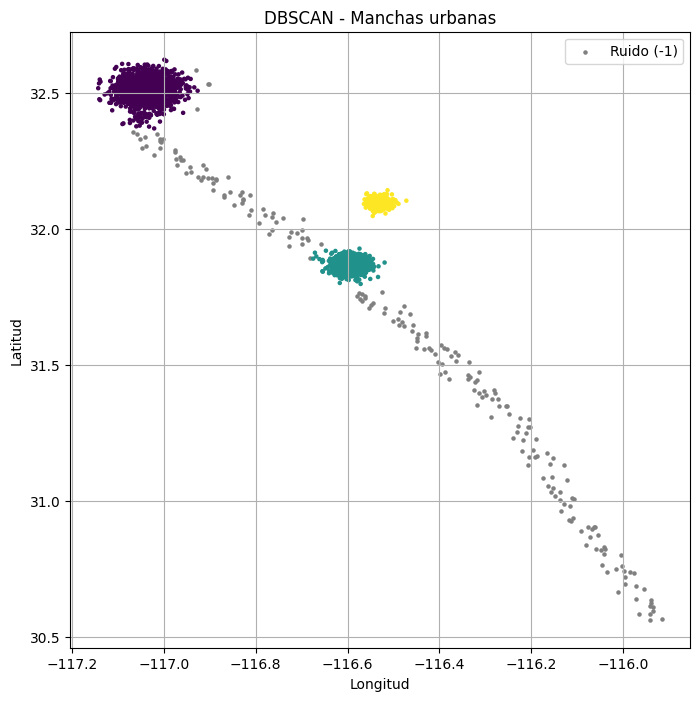

In [7]:
ruido = df[df['Cluster'] == -1]
urbanos = df[df['Cluster'] != -1]

plt.figure(figsize=(8, 8))
plt.scatter(ruido['Longitud'], ruido['Latitud'], c='gray', s=5, label='Ruido (-1)')
plt.scatter(urbanos['Longitud'], urbanos['Latitud'], c=urbanos['Cluster'], cmap='viridis', s=5)
plt.title('DBSCAN - Manchas urbanas')
plt.xlabel('Longitud')
plt.ylabel('Latitud')
plt.legend()
plt.grid()
plt.show()

In [ ]:
display(urbanos.groupby('Cluster')[['Latitud', 'Longitud']].mean())

,Latitud,Longitud
Cluster,,
0,32.512586,-117.037141
1,31.867229,-116.595587
2,32.096538,-116.530044


**¿Usaron el mismo algoritmo?** No. En la Fase 2 usamos K-Means y aquí DBSCAN.

**¿Por qué se comportaron diferente?** K-Means busca centros y asigna todos los puntos a alguno, así que el ruido rural deforma los clusters. DBSCAN agrupa por densidad: un punto solo forma parte de un cluster si tiene al menos min_samples vecinos dentro de un radio. Los ranchos aislados no cumplen eso, por lo que quedan como ruido y no afectan a las ciudades. Además, DBSCAN no necesita que le digamos el número de clusters.

**¿A qué ciudades corresponden las 3 manchas?**
- Cluster 0 (~32.51, -117.03) -> Tijuana
- Cluster 1 (~31.87, -116.60) -> Ensenada
- Cluster 2 (~32.10, -116.52) -> Valle de Guadalupe
